# Ejercicio 4: ¿Es posible reconstruir la imagen de manera única?

En este ejercicio analizamos si las mediciones producidas por distintas matrices de proyección contienen información suficiente para recuperar una imagen de $8\times8$ de manera única. Para ello, estudiamos el rango y el espacio nulo de las matrices $A_2$, $A_4$ y $A_7$, y utilizamos la descomposición SVD para construir dos imágenes diferentes que producen aproximadamente las mismas mediciones.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## a) Condición para una reconstrucción única

La matriz $A \in \mathbb{R}^{m \times 64}$ transforma los 64 valores de los píxeles de la imagen en las $m$ mediciones obtenidas por los rayos:

$$
b = Ax
$$

Para que la imagen pueda reconstruirse de manera única, el sistema $Ax=b$ debe tener una única solución. Esto sucede cuando las 64 columnas de $A$ son linealmente independientes, es decir, cuando la matriz tiene rango columna completo:

$$
\operatorname{rango}(A)=64
$$

El espacio nulo de $A$ está formado por todos los vectores $v$ que cumplen:

$$
Av=0
$$

Si existe un vector no nulo $v$ tal que $Av=0$, entonces las imágenes representadas por $x$ y $x+v$ producen exactamente las mismas mediciones, porque:

$$
A(x+v)=Ax+Av=b+0=b
$$

Por lo tanto, las mediciones no permiten distinguir entre $x$ y $x+v$, y la reconstrucción no es única. El vector $v$ representa una modificación de la imagen que los rayos utilizados no pueden detectar.

Según el teorema de rango y nulidad:

$$
\operatorname{rango}(A)+\dim(\operatorname{Nul}(A))=64
$$

Por lo tanto:

$$
\dim(\operatorname{Nul}(A))=64-\operatorname{rango}(A)
$$

Si $\operatorname{rango}(A)=64$, entonces:

$$
\dim(\operatorname{Nul}(A))=0
$$

En ese caso, el espacio nulo contiene únicamente al vector cero y la reconstrucción puede ser única. En cambio, si $\operatorname{rango}(A)<64$, el espacio nulo contiene vectores no nulos y existen distintas imágenes capaces de producir las mismas mediciones.

Además, como:

$$
\operatorname{rango}(A)\leq \min(m,64)
$$

es necesario contar con al menos 64 rayos, es decir, $m\geq64$. Sin embargo, tener 64 rayos o más no garantiza por sí solo una reconstrucción única, ya que algunos rayos podrían aportar información repetida o linealmente dependiente.

## b) Rango y espacio nulo de las matrices de proyección

Construimos las matrices $A_2$, $A_4$ y $A_7$ utilizando una cantidad creciente de direcciones. Para cada matriz calculamos sus dimensiones, su rango y la dimensión de su espacio nulo. A partir de estos resultados, analizamos si las mediciones permiten recuperar una imagen de manera única e identificamos la presencia de mediciones redundantes.

In [2]:
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

x_fantoma = X_fantoma.reshape(-1)

def mascara_rayo(n, direccion, s):

    matriz = np.array([[0] * n for _ in range(n)])      # creamos una matriz de n x n de ceros

    for i in range(0, n):      
        for j in range(0, n):
            if direccion[0] * i + direccion[1] * j == s:        # comprobamos si el píxel (i, j) pertenece al rayo
                matriz[i, j] = 1        # si pertenece al rayo, marcamos esa posición con un 1

    return matriz       # devolvemos la máscara del rayo


def matriz_proyeccion(n, direcciones):

    matriz = []     # acá vamos a guardar los vectores de todas las máscaras
    rayo = []       # acá vamos a guardar los pares de s y (alfa, beta) de cada rayo

    for direccion in direcciones:

        valores_s = []      # acá guardamos todos los valores posibles de s para la dirección actual

        # recorremos todos los píxeles
        for i in range(n):
            for j in range(n):
                valores_s.append(direccion[0] * i + direccion[1] * j)       # calculamos el valor de s que le corresponde al píxel (i, j) para esta dirección

        valores_s = sorted(set(valores_s))      # eliminamos los valores repetidos de s y los ordenamos de menor a mayor

        for s in valores_s:

            rayo.append((tuple(direccion), s))

            mascara = mascara_rayo(n, direccion, s)     # generamos la máscara de este rayo particular
            matriz.append(mascara.reshape(-1))      # convertimos la máscara de n x n en un vector y lo agregamos como una nueva fila

    return np.array(matriz) , rayo



In [3]:
D2 = [(1, 0), (0, 1)]
A2, rayos_A2 = matriz_proyeccion(8, D2)
print (f"Dimensiones de A2: {A2.shape}")

rango_A2 = np.linalg.matrix_rank(A2)
print (f"Rango de A2: {rango_A2}")

nul_A2 = 64 - rango_A2
print(f"Dimensión del espacio nulo: {nul_A2}")

if (nul_A2 == 0):
    print ("Permite determinar una imagen de manera única!")
else :
    print ("No permite determinar una imagen de manera única!")





Dimensiones de A2: (16, 64)
Rango de A2: 15
Dimensión del espacio nulo: 49
No permite determinar una imagen de manera única!


In [4]:
D4 = D2 + [(1, 1), (1, -1)]
A4, rayos_A4 = matriz_proyeccion(8, D4)
print (f"Dimensiones de A4: {A4.shape}")

rango_A4 = np.linalg.matrix_rank(A4)
print (f"Rango de A4: {rango_A4}")

nul_A4 = 64 - rango_A4
print(f"Dimensión del espacio nulo: {nul_A4}")

if (nul_A4 == 0):
    print ("Permite determinar una imagen de manera única!")
else :
    print ("No permite determinar una imagen de manera única!")



Dimensiones de A4: (46, 64)
Rango de A4: 39
Dimensión del espacio nulo: 25
No permite determinar una imagen de manera única!


In [5]:
D7 = D4 + [(2, 1), (1, 2), (3, 1)]
A7, rayos_A7 = matriz_proyeccion(8, D7)
print (f"Dimensiones de A7: {A7.shape}")

rango_A7 = np.linalg.matrix_rank(A7)
print (f"Rango de A7: {rango_A7}")

nul_A7 = 64 - rango_A7
print(f"Dimensión del espacio nulo: {nul_A7}")

if (nul_A7 == 0):
    print ("Permite determinar una imagen de manera única!")
else :
    print ("No permite determinar una imagen de manera única!")

Dimensiones de A7: (119, 64)
Rango de A7: 64
Dimensión del espacio nulo: 0
Permite determinar una imagen de manera única!


Para $A_2$ obtuvimos una matriz de dimensiones $16\times64$ y rango 15. Por lo tanto, la dimensión de su espacio nulo es 49 y no podemos determinar una imagen de manera única. Además, como la matriz tiene 16 filas, pero solamente 15 son linealmente independientes, identificamos una medición redundante.

Para $A_4$ obtuvimos una matriz de dimensiones $46\times64$ y rango 39. En este caso, la dimensión de su espacio nulo es 25, por lo que tampoco podemos determinar una imagen de manera única. La diferencia entre sus 46 filas y su rango muestra que existen 7 mediciones redundantes.

Tanto $A_2$ como $A_4$ tienen menos de 64 filas, por lo que su rango máximo posible es inferior a 64. En consecuencia, incluso si todas sus mediciones fueran linealmente independientes, no contaríamos con información suficiente para determinar los 64 píxeles de manera única.

Para $A_7$ obtuvimos una matriz de dimensiones $119\times64$ y rango 64. Como alcanza el máximo rango posible y la dimensión de su espacio nulo es cero, podemos determinar una imagen de manera única. Sin embargo, de las 119 mediciones, solamente 64 son linealmente independientes, por lo que identificamos 55 mediciones redundantes.

En conclusión, al agregar nuevas direcciones aumentamos la información disponible, aunque no todos los rayos incorporados aportan información linealmente independiente. Solo con $A_7$ alcanzamos rango 64 y reunimos información suficiente para reconstruir una imagen de $8\times8$ de manera única.

## c) Construcción de una imagen alternativa mediante SVD

Como $A_4$ tiene un espacio nulo de dimensión 25, sabemos que existen vectores no nulos que producen mediciones aproximadamente iguales a cero. Mediante la descomposición SVD elegimos uno de esos vectores y lo utilizamos para modificar el fantoma sin alterar de manera significativa sus mediciones.

In [6]:
# Calculamos la descomposición SVD de A4
U, S, Vt = np.linalg.svd(A4, full_matrices=True)

# Elegimos la última fila de Vt, que pertenece al espacio nulo de A4
v = Vt[-1]

# Verificamos que v no sea el vector cero
norma_v = np.linalg.norm(v)

# Verificamos que A4 @ v sea aproximadamente cero
norma_A4v = np.linalg.norm(A4 @ v)

print(f"Norma de v: {norma_v}")
print(f"Norma de A4v: {norma_A4v}")

Norma de v: 1.0
Norma de A4v: 1.699815066750582e-15


In [7]:
# Calculamos las mediciones del fantoma original
b4 = A4 @ x_fantoma

# Elegimos un valor de gamma distinto de cero
gamma = 0.9

# Construimos la imagen alternativa
x_alt = x_fantoma + gamma * v

# Calculamos sus mediciones
b4_alt = A4 @ x_alt

# Comparamos las mediciones de ambas imágenes
diferencia_b = np.linalg.norm(b4_alt - b4)

print(f"Diferencia entre las mediciones: {diferencia_b}")
print("¿Las mediciones son aproximadamente iguales?", np.allclose(b4, b4_alt))

Diferencia entre las mediciones: 1.9401693768729497e-15
¿Las mediciones son aproximadamente iguales? True


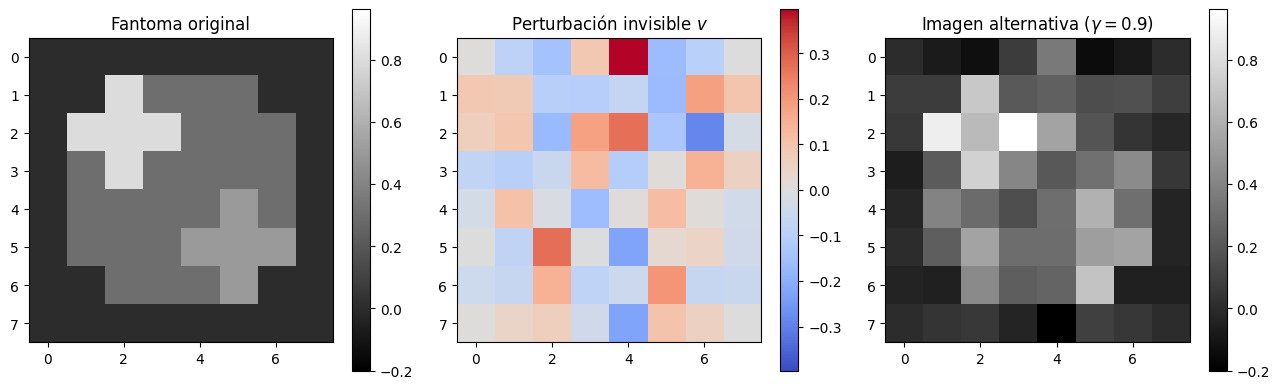

In [8]:
# Recuperamos las representaciones matriciales
X_alt = x_alt.reshape(8, 8)
V = v.reshape(8, 8)

# Calculamos una escala común para comparar ambas imágenes
vmin_imagenes = min(X_fantoma.min(), X_alt.min())
vmax_imagenes = max(X_fantoma.max(), X_alt.max())

# Usamos una escala simétrica para los valores positivos y negativos de v
limite_v = np.max(np.abs(V))

fig, ax = plt.subplots(1, 3, figsize=(13, 4))

im0 = ax[0].imshow(
    X_fantoma,
    cmap="gray",
    vmin=vmin_imagenes,
    vmax=vmax_imagenes
)
ax[0].set_title("Fantoma original")
plt.colorbar(im0, ax=ax[0])

im1 = ax[1].imshow(
    V,
    cmap="coolwarm",
    vmin=-limite_v,
    vmax=limite_v
)
ax[1].set_title("Perturbación invisible $v$")
plt.colorbar(im1, ax=ax[1])

im2 = ax[2].imshow(
    X_alt,
    cmap="gray",
    vmin=vmin_imagenes,
    vmax=vmax_imagenes
)
ax[2].set_title(f"Imagen alternativa ($\\gamma={gamma}$)")
plt.colorbar(im2, ax=ax[2])

plt.tight_layout()
plt.show()

### Interpretación de la información invisible para $A_4$

Al representar el vector $v$ como una matriz de $8\times8$, observamos un patrón formado por valores positivos y negativos. La matriz $A_4$ contiene rayos horizontales, verticales y diagonales en dos sentidos. Al calcular las mediciones de $v$, sus componentes positivas y negativas se compensan a lo largo de todos esos rayos, por lo que obtenemos $A_4v\approx0$.

Luego construimos la imagen alternativa $x_{\mathrm{alt}}=x_{\mathrm{fantoma}}+\gamma v$. Aunque esta imagen es diferente del fantoma original, verificamos que ambas producen aproximadamente las mismas mediciones, ya que $A_4x_{\mathrm{alt}}\approx A_4x_{\mathrm{fantoma}}$.

A partir de este resultado concluimos que $A_4$ no puede detectar las variaciones que pertenecen a su espacio nulo y, por lo tanto, no permite reconstruir una imagen de manera única.

Utilizamos $x_{\mathrm{alt}}$ como una construcción matemática para demostrar esta falta de unicidad. Como puede contener valores negativos de atenuación, no necesariamente representa una imagen físicamente posible.